# Deepfake Audio Detection using Sub-Band Conformer with Frequency Attention
## ASVspoof 2019 LA Benchmark

**Novelty:** Sub-Band Frequency Attention Conformer (SB-FAC) with RawBoost augmentation  
**Dataset:** ASVspoof 2019 Logical Access (LA)  
**Framework:** PyTorch + torchaudio  

### Two Key Contributions

**1. Sub-Band Frequency Attention (Architectural)**  
Instead of processing the full mel spectrogram uniformly, we split it into frequency sub-bands (low/mid/high) and process each through a separate Conformer branch. A learned attention mechanism then weights the importance of each sub-band per sample. This lets the model adapt to different spoofing methods — voice conversion artifacts concentrate in mid-frequency formant regions, while neural vocoder artifacts appear in high frequencies.

**2. RawBoost Augmentation (Training)**  
Domain-specific data augmentation that adds controlled distortions to raw audio during training — linear/non-linear convolutive noise and impulsive signal-dependent additive noise. This technique, used by top ASVspoof competition entries, forces the model to learn robust artifact patterns rather than dataset-specific shortcuts.

---

### Dataset Download

**Option 1 — Kaggle (Recommended):**  
https://www.kaggle.com/datasets/awsaf49/asvpoof-2019-dataset

**Option 2 — Official Edinburgh DataShare (~7.1GB):**  
https://datashare.ed.ac.uk/handle/10283/3336 — download `LA.zip`

After extracting, set `DATA_ROOT` in the next cell to your folder path.

In [1]:
!pip install scipy
# Fix 1: Install soundfile backend for FLAC support
!pip install soundfile pysoundfile

# Fix 2: Test it works
import torchaudio
print("Available backends:", torchaudio.list_audio_backends())

import soundfile as sf
print("soundfile version:", sf.__version__)

# Quick test
import torch
waveform, sr = torchaudio.load(r"C:\Users\Vejey\Downloads\LA\LA\ASVspoof2019_LA_train\flac\LA_T_1138215.flac")
print(f"Loaded OK! Shape: {waveform.shape}, SR: {sr}")

  Using cached PySoundFile-0.9.0.post1-py2.py3.cp26.cp27.cp32.cp33.cp34.cp35.cp36.pp27.pp32.pp33-none-win_amd64.whl.metadata (9.4 kB)
Using cached PySoundFile-0.9.0.post1-py2.py3.cp26.cp27.cp32.cp33.cp34.cp35.cp36.pp27.pp32.pp33-none-win_amd64.whl (671 kB)
Available backends: ['soundfile']
soundfile version: 0.9.0
Loaded OK! Shape: torch.Size([1, 55329]), SR: 16000


In [2]:
# ============================================================
# Cell 1: Install Dependencies
# ============================================================
import subprocess, sys

packages = [
    "torch", "torchaudio", "librosa", "soundfile",
    "scikit-learn", "matplotlib", "seaborn",
    "gradio", "tqdm", "pandas"
]

for pkg in packages:
    try:
        __import__(pkg.replace("-", "_"))
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])
        
print("All dependencies ready.")

All dependencies ready.


In [4]:
# ============================================================
# Cell 2: Imports and Configuration
# ============================================================
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
from torchaudio.models import Conformer
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    roc_curve, classification_report, confusion_matrix,
    accuracy_score, precision_recall_fscore_support
)
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from tqdm import tqdm
from pathlib import Path
import warnings, random, copy
warnings.filterwarnings("ignore")

# ===================== CONFIGURATION =====================
# >>> CHANGE THIS to your extracted dataset path <<<
DATA_ROOT = r"C:\Users\Vejey\Downloads\LA\LA"

# Audio parameters
SAMPLE_RATE = 16000
N_MELS = 80
N_FFT = 2048
HOP_LENGTH = 512
MAX_FRAMES = 400           # ~12.8 seconds of audio

# Sub-band configuration (our architectural novelty)
# Split 80 mel bins into 4 sub-bands
N_SUBBANDS = 4             # low, low-mid, high-mid, high frequency bands
SUBBAND_SIZE = N_MELS // N_SUBBANDS  # 20 bins each

# Model parameters
D_MODEL = 128              # Conformer internal dimension
NUM_HEADS = 4
FFN_DIM = 256
NUM_CONFORMER_LAYERS = 3   # Layers per sub-band branch (smaller = fits GPU)
CONV_KERNEL = 31
DROPOUT = 0.1

# Training parameters
BATCH_SIZE = 24             # Slightly smaller for multi-branch model
EPOCHS = 20
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

# RawBoost augmentation
RAWBOOST_ALGO = 5           # Combined LnL + ISD + SSI
RAWBOOST_PROB = 0.5         # Apply augmentation with 50% probability

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
VRAM: 8.6 GB


## Step 1: Parse Dataset

In [5]:
# ============================================================
# Cell 3: Parse Protocol Files
# ============================================================

def parse_protocol(protocol_path):
    entries = []
    with open(protocol_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 4:
                speaker = parts[0]
                filename = parts[1]
                attack = parts[-2] if len(parts) == 5 else parts[2]
                label = parts[-1]
                entries.append({
                    "speaker": speaker,
                    "filename": filename,
                    "attack": attack,
                    "label": label,
                    "is_spoof": 1 if label == "spoof" else 0
                })
    return pd.DataFrame(entries)

protocol_dir = Path(DATA_ROOT) / "ASVspoof2019_LA_cm_protocols"

train_proto = protocol_dir / "ASVspoof2019.LA.cm.train.trn.txt"
dev_proto = protocol_dir / "ASVspoof2019.LA.cm.dev.trl.txt"
eval_proto = protocol_dir / "ASVspoof2019.LA.cm.eval.trl.txt"

if not train_proto.exists():
    proto_files = list(protocol_dir.glob("*.txt"))
    print("Found protocol files:", [f.name for f in proto_files])
    for f in proto_files:
        if "train" in f.name.lower(): train_proto = f
        elif "dev" in f.name.lower(): dev_proto = f
        elif "eval" in f.name.lower(): eval_proto = f

df_train = parse_protocol(train_proto)
df_dev = parse_protocol(dev_proto)
df_eval = parse_protocol(eval_proto)

print(f"Train: {len(df_train):,} ({(df_train['is_spoof']==0).sum():,} bonafide, {(df_train['is_spoof']==1).sum():,} spoof)")
print(f"Dev:   {len(df_dev):,} ({(df_dev['is_spoof']==0).sum():,} bonafide, {(df_dev['is_spoof']==1).sum():,} spoof)")
print(f"Eval:  {len(df_eval):,} ({(df_eval['is_spoof']==0).sum():,} bonafide, {(df_eval['is_spoof']==1).sum():,} spoof)")

Train: 25,380 (2,580 bonafide, 22,800 spoof)
Dev:   24,844 (2,548 bonafide, 22,296 spoof)
Eval:  71,237 (7,355 bonafide, 63,882 spoof)


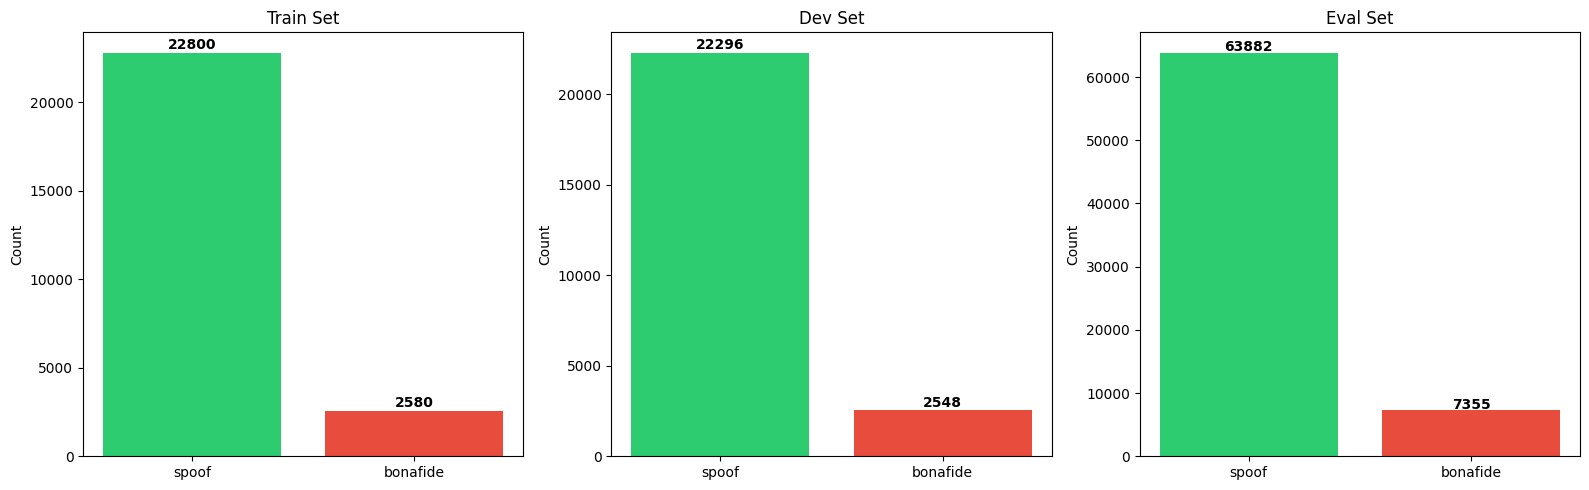


Train attack types: ['A01', 'A02', 'A03', 'A04', 'A05', 'A06']
Eval attack types (UNSEEN): ['A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']


In [6]:
# ============================================================
# Cell 4: Dataset Exploration
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, df) in zip(axes, [("Train", df_train), ("Dev", df_dev), ("Eval", df_eval)]):
    counts = df["label"].value_counts()
    ax.bar(counts.index, counts.values, color=["#2ecc71", "#e74c3c"])
    ax.set_title(f"{name} Set")
    ax.set_ylabel("Count")
    for i, (label, count) in enumerate(counts.items()):
        ax.text(i, count + 200, str(count), ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("dataset_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nTrain attack types:", sorted(df_train[df_train["is_spoof"]==1]["attack"].unique()))
print("Eval attack types (UNSEEN):", sorted(df_eval[df_eval["is_spoof"]==1]["attack"].unique()))

## Step 2: RawBoost Data Augmentation

RawBoost applies domain-specific distortions to raw audio waveforms during training. It was introduced for the ASVspoof challenge and is used by top-performing systems. Three types of noise:

1. **LnL (Linear and Non-linear Convolutive Noise)** — simulates channel effects and non-linear distortions
2. **ISD (Impulsive Signal Dependent Noise)** — adds transient noise proportional to signal amplitude  
3. **SSI (Stationary Signal Independent Noise)** — adds background-type noise

This forces the model to learn genuine spoofing artifacts rather than dataset-specific recording conditions.

In [7]:
# ============================================================
# Cell 5: RawBoost Augmentation
# ============================================================
# Adapted from the official ASVspoof baseline implementation

def rawboost_lnl(x, sr=16000, N_f=5, nBands=5, minF=20, maxF=8000, 
                  minBW=100, maxBW=1000, mincoeff=10, maxcoeff=100,
                  minG=0, maxG=0):
    """Linear and Non-linear Convolutive Noise (LnL)."""
    from scipy.signal import lfilter
    
    y = x.copy().astype(np.float64)  # Use float64 to prevent overflow
    
    for _ in range(N_f):
        fc = np.random.uniform(minF, maxF)
        bw = np.random.uniform(minBW, maxBW)
        c = np.exp(-np.pi * bw / sr)
        d = -2 * c * np.cos(2 * np.pi * fc / sr)
        
        a = np.array([1, d * (1 + c), c**2])
        b = np.array([(1 + c**2) / 2, d * (1 + c), (1 + c**2) / 2])
        
        try:
            y = lfilter(b, a, y)
        except:
            pass
    
    # Mild non-linearity (clamp coefficients to prevent explosion)
    coeffs = np.random.uniform(0.5, 2.0)
    y = y + coeffs * np.tanh(y)  # tanh prevents explosion
    
    # Normalize back to original range
    max_val = np.max(np.abs(y))
    if max_val > 0 and np.isfinite(max_val):
        y = y * (np.max(np.abs(x)) / max_val)
    else:
        y = x.copy()  # Fallback to original if filter diverged
    
    return y.astype(np.float32)


def rawboost_isd(x, sr=16000, P=10, g_sd=2):
    """Impulsive Signal Dependent Noise (ISD).
    Adds transient noise whose amplitude depends on the signal."""
    n_samples = x.shape[0]
    y = x.copy()
    
    # Create impulse noise
    noise_indices = np.random.choice(n_samples, size=int(n_samples * P / 100), replace=False)
    impulse_noise = np.random.normal(0, g_sd, len(noise_indices))
    
    # Scale by local signal amplitude
    y[noise_indices] = y[noise_indices] + impulse_noise * np.abs(y[noise_indices])
    
    return y


def rawboost_ssi(x, sr=16000, SNRmin=10, SNRmax=40):
    """Stationary Signal Independent Noise (SSI).
    Adds stationary background noise at a random SNR."""
    noise = np.random.normal(0, 1, x.shape[0])
    
    SNR = np.random.uniform(SNRmin, SNRmax)
    signal_power = np.mean(x ** 2)
    noise_power = signal_power / (10 ** (SNR / 10))
    
    y = x + np.sqrt(noise_power) * noise
    return y.astype(np.float32)


def apply_rawboost(x, sr=16000, algo=5):
    if algo == 0:
        return x
    
    y = x.copy()
    
    if algo in [1, 4, 5]:
        y = rawboost_lnl(y, sr)
    if algo in [2, 4, 5]:
        y = rawboost_isd(y, sr)
    if algo in [3, 5]:
        y = rawboost_ssi(y, sr)
    
    y = y.astype(np.float32)
    
    # Safety: if augmentation produced NaN/Inf, return original
    if not np.all(np.isfinite(y)):
        return x.copy()
    
    max_val = np.max(np.abs(y))
    if max_val > 0:
        y = y / max_val * np.max(np.abs(x))
    
    return y

# Test RawBoost
test_signal = np.random.randn(16000).astype(np.float32)
augmented = apply_rawboost(test_signal, algo=5)
print(f"Original signal range: [{test_signal.min():.3f}, {test_signal.max():.3f}]")
print(f"Augmented signal range: [{augmented.min():.3f}, {augmented.max():.3f}]")
print("RawBoost augmentation ready.")

Original signal range: [-3.910, 3.944]
Augmented signal range: [-2.256, 3.944]
RawBoost augmentation ready.


## Step 3: Dataset with RawBoost

In [8]:
# ============================================================
# Cell 6: PyTorch Dataset with RawBoost Augmentation
# ============================================================

class ASVspoofDataset(Dataset):
    def __init__(self, protocol_df, audio_dir, sample_rate=16000,
                 n_mels=80, n_fft=2048, hop_length=512, max_frames=400,
                 augment=False, rawboost_prob=0.5, rawboost_algo=5):
        self.df = protocol_df.reset_index(drop=True)
        self.audio_dir = Path(audio_dir)
        self.sample_rate = sample_rate
        self.max_frames = max_frames
        self.augment = augment
        self.rawboost_prob = rawboost_prob
        self.rawboost_algo = rawboost_algo
        
        self.mel_transform = torchaudio.transforms.MelSpectrogram(
            sample_rate=sample_rate, n_fft=n_fft, hop_length=hop_length,
            n_mels=n_mels, power=2.0
        )
        self.amplitude_to_db = torchaudio.transforms.AmplitudeToDB(stype="power")
    
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        audio_path = self.audio_dir / f"{row['filename']}.flac"
        
        waveform, sr = torchaudio.load(str(audio_path))
        
        if sr != self.sample_rate:
            waveform = torchaudio.transforms.Resample(sr, self.sample_rate)(waveform)
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        
        # Apply RawBoost augmentation during training
        if self.augment and random.random() < self.rawboost_prob:
            audio_np = waveform.squeeze().numpy()
            audio_np = apply_rawboost(audio_np, self.sample_rate, self.rawboost_algo)
            waveform = torch.from_numpy(audio_np).unsqueeze(0)
        
        # Extract mel spectrogram
        mel = self.mel_transform(waveform).squeeze(0)  # (n_mels, time)
        mel = self.amplitude_to_db(mel)
        mel = mel.transpose(0, 1)  # (time, n_mels)
        
        # Pad or truncate
        num_frames = mel.shape[0]
        if num_frames > self.max_frames:
            mel = mel[:self.max_frames]
            length = self.max_frames
        else:
            pad = torch.zeros(self.max_frames - num_frames, mel.shape[1])
            mel = torch.cat([mel, pad], dim=0)
            length = num_frames
        
        label = torch.tensor(row["is_spoof"], dtype=torch.float32)
        length = torch.tensor(length, dtype=torch.long)
        
        return mel, label, length

# Create datasets
train_audio_dir = Path(DATA_ROOT) / "ASVspoof2019_LA_train" / "flac"
dev_audio_dir = Path(DATA_ROOT) / "ASVspoof2019_LA_dev" / "flac"
eval_audio_dir = Path(DATA_ROOT) / "ASVspoof2019_LA_eval" / "flac"

train_dataset = ASVspoofDataset(
    df_train, train_audio_dir, SAMPLE_RATE, N_MELS, N_FFT, HOP_LENGTH, MAX_FRAMES,
    augment=True, rawboost_prob=RAWBOOST_PROB, rawboost_algo=RAWBOOST_ALGO
)
dev_dataset = ASVspoofDataset(df_dev, dev_audio_dir, SAMPLE_RATE, N_MELS, N_FFT, HOP_LENGTH, MAX_FRAMES)
eval_dataset = ASVspoofDataset(df_eval, eval_audio_dir, SAMPLE_RATE, N_MELS, N_FFT, HOP_LENGTH, MAX_FRAMES)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
dev_loader = DataLoader(dev_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
eval_loader = DataLoader(eval_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

mel, label, length = train_dataset[0]
print(f"Mel shape: {mel.shape} | Label: {label.item()} | Frames: {length.item()}")
print(f"Train: {len(train_loader)} batches | Dev: {len(dev_loader)} | Eval: {len(eval_loader)}")

Mel shape: torch.Size([400, 80]) | Label: 0.0 | Frames: 109
Train: 1058 batches | Dev: 1036 | Eval: 2969


## Step 4: Sub-Band Frequency Attention Conformer (SB-FAC)

**This is the core architectural novelty.** The model works as follows:

1. **Split** the mel spectrogram into K frequency sub-bands (e.g., 4 bands of 20 bins each)
2. **Process** each sub-band through its own lightweight Conformer branch
3. **Attend** — a learned attention mechanism weights each sub-band's importance per sample
4. **Fuse** the weighted sub-band representations
5. **Classify** bonafide vs. spoof

**Why this works:** Different spoofing algorithms leave artifacts in different frequency regions:
- **Low band (0-2kHz):** Fundamental frequency, first formant — usually well-reproduced by all methods
- **Low-mid band (2-4kHz):** Higher formants — voice conversion distorts these
- **High-mid band (4-6kHz):** Fricatives, sibilants — synthesis artifacts appear here
- **High band (6-8kHz):** Neural vocoders often attenuate or add noise here

The sub-band attention learns to focus on the most discriminative band for each input sample.

In [9]:
# ============================================================
# Cell 7: Sub-Band Frequency Attention Conformer (SB-FAC)
# ============================================================

class SubBandAttention(nn.Module):
    """Learns to weight the importance of each frequency sub-band.
    
    For each input sample, produces attention weights over K sub-bands,
    allowing the model to focus on frequency regions that contain the
    most discriminative spoofing artifacts.
    
    Different spoofing algorithms leave artifacts in different bands:
    - Voice conversion: mid-frequency formant distortions
    - Neural vocoders: high-frequency attenuation/artifacts  
    - Replay attacks: full-band room acoustics
    """
    
    def __init__(self, d_model, n_subbands):
        super().__init__()
        self.n_subbands = n_subbands
        
        # Squeeze-and-excitation style attention
        # Takes concatenated sub-band features, outputs per-band weights
        self.attention = nn.Sequential(
            nn.Linear(d_model * n_subbands, d_model),
            nn.ReLU(),
            nn.Linear(d_model, n_subbands),
            nn.Softmax(dim=-1)
        )
    
    def forward(self, subband_features):
        """
        Args:
            subband_features: list of K tensors, each (batch, d_model)
        Returns:
            fused: (batch, d_model) — attention-weighted fusion
            weights: (batch, K) — attention weights (for visualization)
        """
        # Concatenate all sub-band features
        concat = torch.cat(subband_features, dim=-1)  # (batch, d_model * K)
        
        # Compute attention weights
        weights = self.attention(concat)  # (batch, K)
        
        # Weighted sum of sub-band features
        stacked = torch.stack(subband_features, dim=1)  # (batch, K, d_model)
        fused = (stacked * weights.unsqueeze(-1)).sum(dim=1)  # (batch, d_model)
        
        return fused, weights


class SubBandConformer(nn.Module):
    """Sub-Band Frequency Attention Conformer (SB-FAC).
    
    Architecture:
        Input: mel spectrogram (batch, time, n_mels)
        
        1. Split into K frequency sub-bands:
           [0:20], [20:40], [40:60], [60:80] mel bins
        
        2. Each sub-band -> Linear projection -> Conformer encoder
           (separate parameters per branch, shared architecture)
        
        3. Temporal pooling per branch -> K feature vectors
        
        4. Sub-Band Attention: learn which bands matter for this sample
        
        5. Classification head on fused representation
    """
    
    def __init__(self, n_mels=80, n_subbands=4, d_model=128, num_heads=4,
                 ffn_dim=256, num_layers=3, conv_kernel=31, dropout=0.1):
        super().__init__()
        
        self.n_subbands = n_subbands
        self.subband_size = n_mels // n_subbands
        self.d_model = d_model
        
        # Per-subband projection and Conformer
        self.projections = nn.ModuleList([
            nn.Sequential(
                nn.Linear(self.subband_size, d_model),
                nn.LayerNorm(d_model),
                nn.Dropout(dropout)
            ) for _ in range(n_subbands)
        ])
        
        self.conformers = nn.ModuleList([
            Conformer(
                input_dim=d_model,
                num_heads=num_heads,
                ffn_dim=ffn_dim,
                num_layers=num_layers,
                depthwise_conv_kernel_size=conv_kernel,
                dropout=dropout,
                use_group_norm=True
            ) for _ in range(n_subbands)
        ])
        
        # Temporal pooling per branch (attentive)
        self.temporal_pools = nn.ModuleList([
            nn.Sequential(nn.Linear(d_model, 1), nn.Softmax(dim=1))
            for _ in range(n_subbands)
        ])
        
        # Sub-band frequency attention (our novelty)
        self.subband_attention = SubBandAttention(d_model, n_subbands)
        
        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )
    
    def forward(self, mel, lengths):
        """
        Args:
            mel: (batch, time, n_mels)
            lengths: (batch,)
        Returns:
            logits: (batch, 1)
            subband_weights: (batch, n_subbands) for interpretability
        """
        batch_size = mel.size(0)
        max_len = mel.size(1)
        
        # Create padding mask
        mask = torch.arange(max_len, device=mel.device).unsqueeze(0) < lengths.unsqueeze(1)
        mask = mask.unsqueeze(2).float()  # (batch, time, 1)
        
        subband_features = []
        
        for i in range(self.n_subbands):
            # Extract sub-band: slice along frequency axis
            start = i * self.subband_size
            end = start + self.subband_size
            sb = mel[:, :, start:end]  # (batch, time, subband_size)
            
            # Project to d_model
            sb = self.projections[i](sb)  # (batch, time, d_model)
            
            # Conformer encoding
            full_lengths = torch.full_like(lengths, sb.size(1))
            sb, _ = self.conformers[i](sb, full_lengths)
            
            # Masked attentive temporal pooling
            attn = self.temporal_pools[i](sb) * mask
            attn = attn / (attn.sum(dim=1, keepdim=True) + 1e-8)
            pooled = (sb * attn).sum(dim=1)  # (batch, d_model)
            
            subband_features.append(pooled)
        
        # Sub-band frequency attention fusion
        fused, subband_weights = self.subband_attention(subband_features)
        
        # Classify
        logits = self.classifier(fused)
        
        return logits, subband_weights


# Create model
model = SubBandConformer(
    n_mels=N_MELS,
    n_subbands=N_SUBBANDS,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    ffn_dim=FFN_DIM,
    num_layers=NUM_CONFORMER_LAYERS,
    conv_kernel=CONV_KERNEL,
    dropout=DROPOUT
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Model size:           {total_params * 4 / 1e6:.1f} MB (float32)")

# Verify forward pass
dummy_mel = torch.randn(2, MAX_FRAMES, N_MELS).to(DEVICE)
dummy_len = torch.tensor([MAX_FRAMES, 200]).to(DEVICE)
with torch.no_grad():
    logits, weights = model(dummy_mel, dummy_len)
print(f"\nForward pass OK:")
print(f"  Logits shape: {logits.shape}")
print(f"  Sub-band weights: {weights[0].cpu().numpy().round(3)}")
print(f"  (Weights sum to {weights[0].sum().item():.4f})")

Total parameters:     3,123,465
Trainable parameters: 3,123,465
Model size:           12.5 MB (float32)

Forward pass OK:
  Logits shape: torch.Size([2, 1])
  Sub-band weights: [0.287 0.209 0.255 0.248]
  (Weights sum to 1.0000)


## Step 5: Training

In [10]:
# ============================================================
# Cell 8: Training Utilities
# ============================================================

def compute_eer(labels, scores):
    fpr, tpr, thresholds = roc_curve(labels, scores, pos_label=1)
    fnr = 1 - tpr
    eer_idx = np.argmin(np.abs(fpr - fnr))
    eer = (fpr[eer_idx] + fnr[eer_idx]) / 2
    return eer, thresholds[eer_idx]

# Class weights for imbalanced data
n_bonafide = (df_train["is_spoof"] == 0).sum()
n_spoof = (df_train["is_spoof"] == 1).sum()
w_bonafide = len(df_train) / (2 * n_bonafide)
w_spoof = len(df_train) / (2 * n_spoof)
pos_weight = torch.tensor([w_bonafide / w_spoof]).to(DEVICE)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

print(f"Class weights — Bonafide: {w_bonafide:.3f}, Spoof: {w_spoof:.3f}")
print(f"Loss pos_weight: {pos_weight.item():.3f}")

Class weights — Bonafide: 4.919, Spoof: 0.557
Loss pos_weight: 8.837


In [11]:
# ============================================================
# Cell 9: Training and Evaluation Functions
# ============================================================

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    all_labels, all_scores = [], []
    
    pbar = tqdm(loader, desc="Training", leave=False)
    for mel, labels, lengths in pbar:
        mel, labels, lengths = mel.to(device), labels.to(device), lengths.to(device)
        
        optimizer.zero_grad()
        logits, _ = model(mel, lengths)
        loss = criterion(logits.squeeze(1), labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        
        total_loss += loss.item() * mel.size(0)
        all_labels.extend(labels.cpu().numpy())
        all_scores.extend(torch.sigmoid(logits.squeeze(1)).detach().cpu().numpy())
        pbar.set_postfix(loss=f"{loss.item():.4f}")
    
    avg_loss = total_loss / len(loader.dataset)
    eer, _ = compute_eer(np.array(all_labels), np.array(all_scores))
    acc = accuracy_score(np.array(all_labels), (np.array(all_scores) > 0.5).astype(int))
    return avg_loss, eer, acc


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_labels, all_scores, all_sb_weights = [], [], []
    
    for mel, labels, lengths in tqdm(loader, desc="Evaluating", leave=False):
        mel, labels, lengths = mel.to(device), labels.to(device), lengths.to(device)
        
        logits, sb_weights = model(mel, lengths)
        loss = criterion(logits.squeeze(1), labels)
        
        total_loss += loss.item() * mel.size(0)
        all_labels.extend(labels.cpu().numpy())
        all_scores.extend(torch.sigmoid(logits.squeeze(1)).cpu().numpy())
        all_sb_weights.extend(sb_weights.cpu().numpy())
    
    all_labels = np.array(all_labels)
    all_scores = np.array(all_scores)
    all_sb_weights = np.array(all_sb_weights)
    
    avg_loss = total_loss / len(loader.dataset)
    eer, threshold = compute_eer(all_labels, all_scores)
    acc = accuracy_score(all_labels, (all_scores > 0.5).astype(int))
    
    return avg_loss, eer, threshold, acc, all_labels, all_scores, all_sb_weights

In [20]:
# ============================================================
# ROUND 2: Fixed Sub-Band Attention + Better Regularization
# ============================================================

class SubBandAttentionV2(nn.Module):
    """Fixed: Sigmoid instead of Softmax prevents winner-take-all."""
    def __init__(self, d_model, n_subbands):
        super().__init__()
        self.n_subbands = n_subbands
        self.attention = nn.Sequential(
            nn.Linear(d_model * n_subbands, d_model),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(d_model, n_subbands),
            nn.Sigmoid()
        )
    def forward(self, subband_features):
        concat = torch.cat(subband_features, dim=-1)
        weights = self.attention(concat)
        weights = weights / (weights.sum(dim=-1, keepdim=True) + 1e-8)
        stacked = torch.stack(subband_features, dim=1)
        fused = (stacked * weights.unsqueeze(-1)).sum(dim=1)
        return fused, weights

class SubBandConformerV2(nn.Module):
    """V2: Fixed attention + diversity loss."""
    def __init__(self, n_mels=80, n_subbands=4, d_model=128, num_heads=4,
                 ffn_dim=256, num_layers=3, conv_kernel=31, dropout=0.2):
        super().__init__()
        self.n_subbands = n_subbands
        self.subband_size = n_mels // n_subbands
        self.d_model = d_model
        
        self.projections = nn.ModuleList([
            nn.Sequential(nn.Linear(self.subband_size, d_model),
                          nn.LayerNorm(d_model), nn.Dropout(dropout))
            for _ in range(n_subbands)])
        
        self.conformers = nn.ModuleList([
            Conformer(input_dim=d_model, num_heads=num_heads, ffn_dim=ffn_dim,
                      num_layers=num_layers, depthwise_conv_kernel_size=conv_kernel,
                      dropout=dropout, use_group_norm=True)
            for _ in range(n_subbands)])
        
        self.temporal_pools = nn.ModuleList([
            nn.Sequential(nn.Linear(d_model, 1), nn.Softmax(dim=1))
            for _ in range(n_subbands)])
        
        self.subband_attention = SubBandAttentionV2(d_model, n_subbands)
        
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))
    
    def forward(self, mel, lengths):
        max_len = mel.size(1)
        mask = (torch.arange(max_len, device=mel.device).unsqueeze(0) < lengths.unsqueeze(1)).unsqueeze(2).float()
        
        subband_features = []
        for i in range(self.n_subbands):
            sb = mel[:, :, i*self.subband_size:(i+1)*self.subband_size]
            sb = self.projections[i](sb)
            full_lengths = torch.full_like(lengths, sb.size(1))
            sb, _ = self.conformers[i](sb, full_lengths)
            attn = self.temporal_pools[i](sb) * mask
            attn = attn / (attn.sum(dim=1, keepdim=True) + 1e-8)
            subband_features.append((sb * attn).sum(dim=1))
        
        fused, subband_weights = self.subband_attention(subband_features)
        return self.classifier(fused), subband_weights
    
    def attention_diversity_loss(self, subband_weights):
        """Pushes weights toward uniform — prevents collapse."""
        uniform = torch.ones_like(subband_weights) / self.n_subbands
        return F.kl_div(torch.log(subband_weights + 1e-8), uniform, reduction='batchmean')

# Label smoothing loss
class LabelSmoothingBCELoss(nn.Module):
    def __init__(self, smoothing=0.05, pos_weight=None):
        super().__init__()
        self.smoothing = smoothing
        self.bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    def forward(self, logits, targets):
        targets_smooth = targets * (1 - self.smoothing) + (1 - targets) * self.smoothing
        return self.bce(logits, targets_smooth)

# Create V2 model
model2 = SubBandConformerV2(
    n_mels=N_MELS, n_subbands=N_SUBBANDS, d_model=D_MODEL,
    num_heads=NUM_HEADS, ffn_dim=FFN_DIM, num_layers=NUM_CONFORMER_LAYERS,
    conv_kernel=CONV_KERNEL, dropout=0.2
).to(DEVICE)

print(f"V2 Parameters: {sum(p.numel() for p in model2.parameters()):,}")

optimizer2 = torch.optim.AdamW(model2.parameters(), lr=1e-4, weight_decay=5e-4)
scheduler2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer2, T_max=30, eta_min=1e-6)
criterion2 = LabelSmoothingBCELoss(smoothing=0.05, pos_weight=pos_weight)

train_dataset.rawboost_prob = 0.7
train_loader2 = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)

DIVERSITY_WEIGHT = 0.1

history2 = {"train_loss": [], "train_eer": [], "train_acc": [],
            "val_loss": [], "val_eer": [], "val_acc": []}
best_val_eer2 = float("inf")
best_epoch2 = 0

print("=" * 70)
print("ROUND 2: Sigmoid attention + diversity loss + label smoothing")
print("=" * 70)

for epoch in range(1, 31):
    model2.train()
    total_loss = 0
    all_labels, all_scores = [], []
    
    pbar = tqdm(train_loader2, desc=f"Epoch {epoch:02d}", leave=False)
    for mel, labels, lengths in pbar:
        mel, labels, lengths = mel.to(DEVICE), labels.to(DEVICE), lengths.to(DEVICE)
        optimizer2.zero_grad()
        logits, sb_weights = model2(mel, lengths)
        
        cls_loss = criterion2(logits.squeeze(1), labels)
        div_loss = model2.attention_diversity_loss(sb_weights)
        loss = cls_loss + DIVERSITY_WEIGHT * div_loss
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model2.parameters(), max_norm=5.0)
        optimizer2.step()
        
        total_loss += cls_loss.item() * mel.size(0)
        all_labels.extend(labels.cpu().numpy())
        all_scores.extend(torch.sigmoid(logits.squeeze(1)).detach().cpu().numpy())
        pbar.set_postfix(loss=f"{loss.item():.4f}")
    
    train_loss = total_loss / len(train_loader2.dataset)
    train_eer, _ = compute_eer(np.array(all_labels), np.array(all_scores))
    train_acc = accuracy_score(np.array(all_labels), (np.array(all_scores) > 0.5).astype(int))
    
    val_loss, val_eer, val_thresh, val_acc, _, _, val_sb = evaluate(model2, dev_loader, criterion, DEVICE)
    scheduler2.step()
    
    history2["train_loss"].append(train_loss)
    history2["train_eer"].append(train_eer)
    history2["train_acc"].append(train_acc)
    history2["val_loss"].append(val_loss)
    history2["val_eer"].append(val_eer)
    history2["val_acc"].append(val_acc)
    
    if val_eer < best_val_eer2:
        best_val_eer2 = val_eer
        best_epoch2 = epoch
        torch.save({"epoch": epoch, "model_state_dict": model2.state_dict(),
                     "val_eer": val_eer, "val_acc": val_acc, "threshold": val_thresh},
                    "best_sbfac_v2.pth")
    
    avg_w = val_sb.mean(axis=0)
    w_str = " | ".join([f"B{i}:{avg_w[i]:.2f}" for i in range(N_SUBBANDS)])
    star = " ★" if val_eer <= best_val_eer2 else ""
    print(f"Epoch {epoch:02d}/30 | Train EER:{train_eer:.4f} | "
          f"Val EER:{val_eer:.4f} Acc:{val_acc:.4f} | Bands: {w_str}{star}")

print(f"\nBest: epoch {best_epoch2}, Val EER: {best_val_eer2:.4f}")

V2 Parameters: 3,123,465
ROUND 2: Sigmoid attention + diversity loss + label smoothing


Epoch 01/30 | Train EER:0.2981 | Val EER:0.0927 Acc:0.8974 | Bands: B0:0.28 | B1:0.24 | B2:0.24 | B3:0.24 ★


Epoch 02/30 | Train EER:0.1163 | Val EER:0.0741 Acc:0.9310 | Bands: B0:0.23 | B1:0.25 | B2:0.26 | B3:0.26 ★


Epoch 03/30 | Train EER:0.0824 | Val EER:0.0643 Acc:0.9455 | Bands: B0:0.25 | B1:0.24 | B2:0.25 | B3:0.27 ★


Epoch 04/30 | Train EER:0.0610 | Val EER:0.1228 Acc:0.9253 | Bands: B0:0.23 | B1:0.26 | B2:0.25 | B3:0.26


Epoch 05/30 | Train EER:0.0508 | Val EER:0.0578 Acc:0.9581 | Bands: B0:0.25 | B1:0.24 | B2:0.25 | B3:0.27 ★


... (21 outputs left out)

Epoch 27/30 | Train EER:0.0075 | Val EER:0.0269 Acc:0.9616 | Bands: B0:0.25 | B1:0.24 | B2:0.25 | B3:0.26


Epoch 28/30 | Train EER:0.0083 | Val EER:0.0298 Acc:0.9601 | Bands: B0:0.25 | B1:0.24 | B2:0.25 | B3:0.26


Epoch 29/30 | Train EER:0.0080 | Val EER:0.0310 Acc:0.9600 | Bands: B0:0.25 | B1:0.24 | B2:0.25 | B3:0.26


Epoch 30/30 | Train EER:0.0069 | Val EER:0.0305 Acc:0.9604 | Bands: B0:0.25 | B1:0.24 | B2:0.25 | B3:0.26

Best: epoch 16, Val EER: 0.0161


## Step 6: Evaluation and Analysis

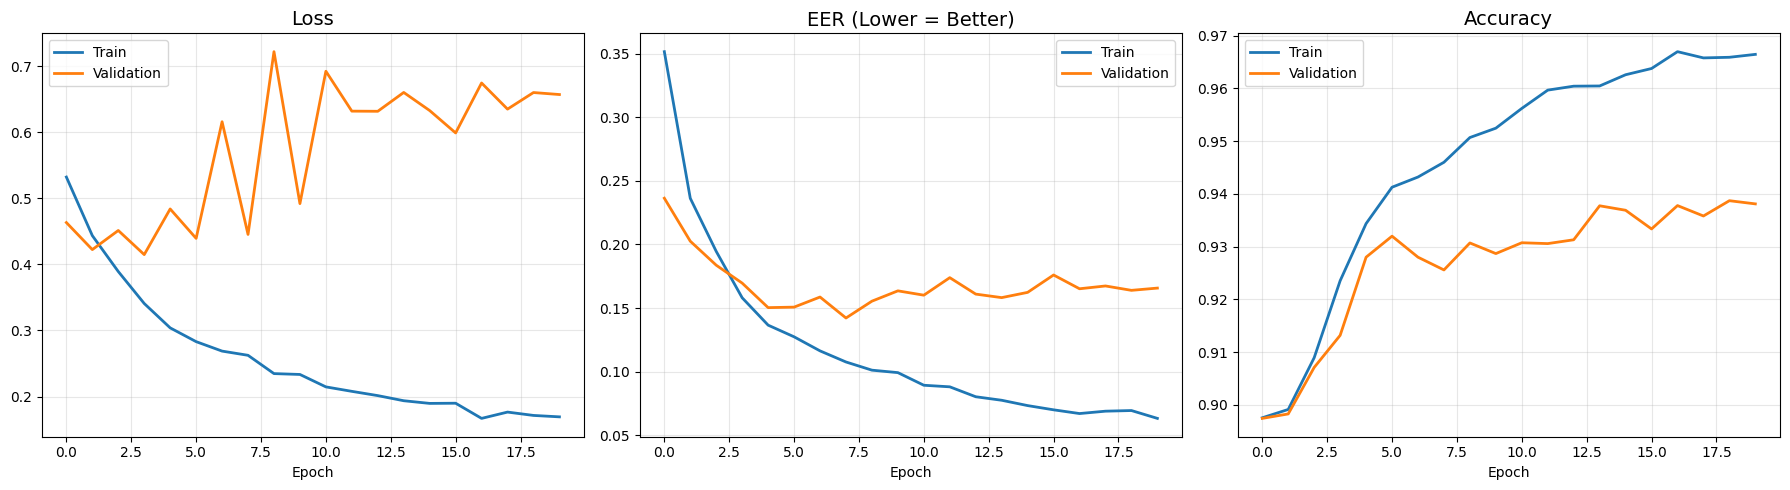

In [21]:
# ============================================================
# Cell 11: Training Curves
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history["train_loss"], label="Train", linewidth=2)
axes[0].plot(history["val_loss"], label="Validation", linewidth=2)
axes[0].set_title("Loss", fontsize=14); axes[0].set_xlabel("Epoch")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history["train_eer"], label="Train", linewidth=2)
axes[1].plot(history["val_eer"], label="Validation", linewidth=2)
axes[1].set_title("EER (Lower = Better)", fontsize=14); axes[1].set_xlabel("Epoch")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(history["train_acc"], label="Train", linewidth=2)
axes[2].plot(history["val_acc"], label="Validation", linewidth=2)
axes[2].set_title("Accuracy", fontsize=14); axes[2].set_xlabel("Epoch")
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
# ============================================================
# Load best V2 model and evaluate
# ============================================================

checkpoint2 = torch.load("best_sbfac_v2.pth", map_location=DEVICE, weights_only=False)
model2.load_state_dict(checkpoint2["model_state_dict"])
print(f"Loaded best V2 model from epoch {checkpoint2['epoch']}")
print(f"Val EER: {checkpoint2['val_eer']:.4f}")

# Dev set
print("\n" + "="*60 + "\nDEVELOPMENT SET\n" + "="*60)
dev_loss, dev_eer, dev_thresh, dev_acc, dev_labels, dev_scores, dev_sb_weights = evaluate(
    model2, dev_loader, criterion, DEVICE)
print(f"EER: {dev_eer:.4f} ({dev_eer*100:.2f}%) | Accuracy: {dev_acc:.4f}")
print(classification_report(dev_labels, (dev_scores>0.5).astype(int), target_names=["Bonafide","Spoof"]))

# Eval set
print("="*60 + "\nEVAL SET (UNSEEN ATTACKS)\n" + "="*60)
eval_loss, eval_eer, eval_thresh, eval_acc, eval_labels, eval_scores, eval_sb_weights = evaluate(
    model2, eval_loader, criterion, DEVICE)
print(f"EER: {eval_eer:.4f} ({eval_eer*100:.2f}%) | Accuracy: {eval_acc:.4f}")
print(classification_report(eval_labels, (eval_scores>0.5).astype(int), target_names=["Bonafide","Spoof"]))

Loaded best V2 model from epoch 16
Val EER: 0.0161

DEVELOPMENT SET


EER: 0.0161 (1.61%) | Accuracy: 0.9717
              precision    recall  f1-score   support

    Bonafide       1.00      0.72      0.84      2548
       Spoof       0.97      1.00      0.98     22296

    accuracy                           0.97     24844
   macro avg       0.98      0.86      0.91     24844
weighted avg       0.97      0.97      0.97     24844

EVAL SET (UNSEEN ATTACKS)


EER: 0.1123 (11.23%) | Accuracy: 0.8880
              precision    recall  f1-score   support

    Bonafide       0.48      0.89      0.62      7355
       Spoof       0.99      0.89      0.93     63882

    accuracy                           0.89     71237
   macro avg       0.73      0.89      0.78     71237
weighted avg       0.93      0.89      0.90     71237



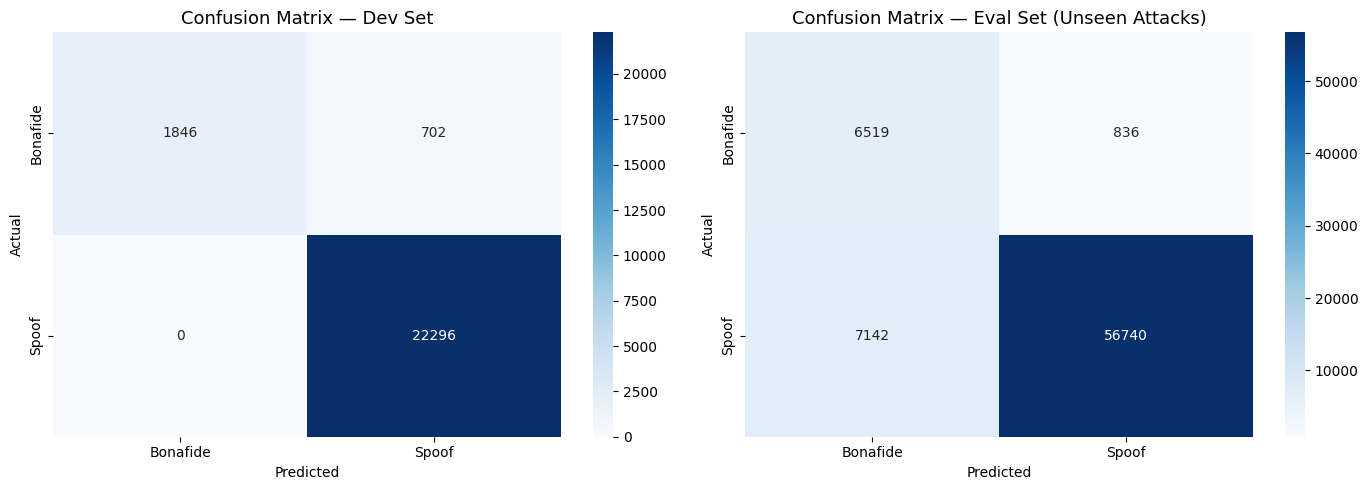

In [24]:
# ============================================================
# Confusion Matrix
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (labels, scores, title) in zip(axes, [
    (dev_labels, dev_scores, "Dev Set"),
    (eval_labels, eval_scores, "Eval Set (Unseen Attacks)")
]):
    cm = confusion_matrix(labels, (scores > 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Bonafide", "Spoof"], yticklabels=["Bonafide", "Spoof"])
    ax.set_title(f"Confusion Matrix — {title}", fontsize=13)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrix_v2.png", dpi=150, bbox_inches="tight")
plt.show()

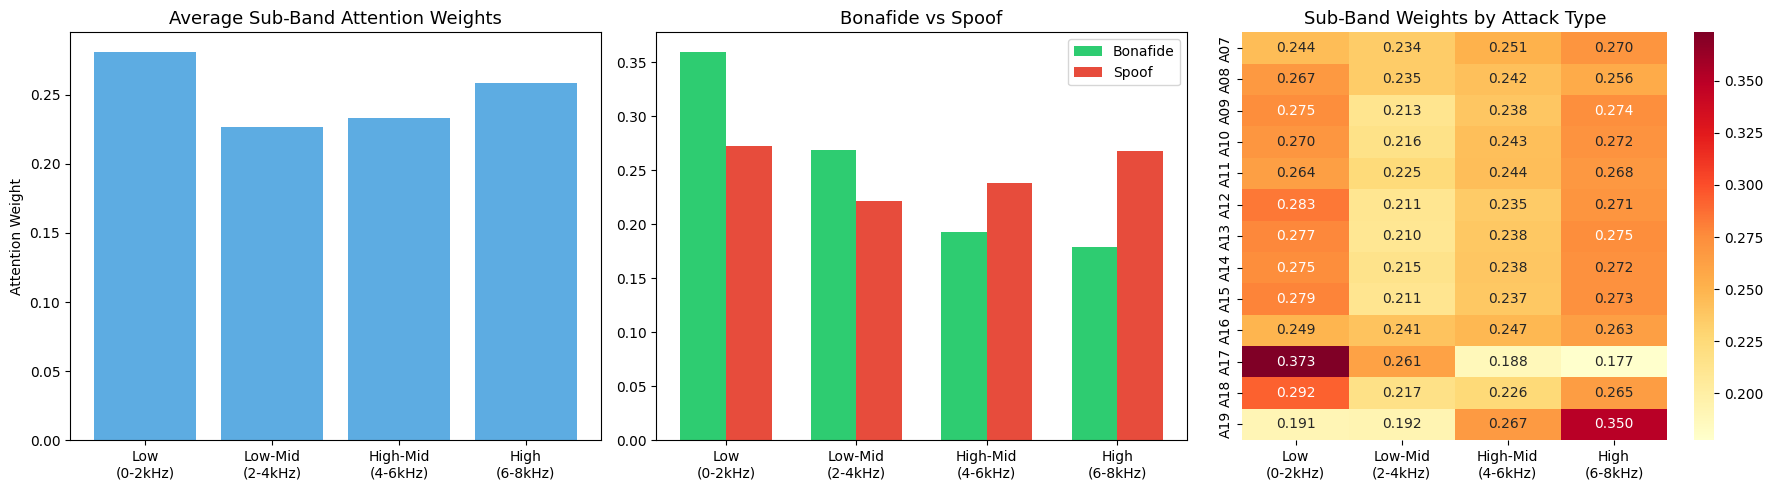

In [25]:
# ============================================================
# Sub-Band Attention Analysis
# ============================================================

band_names = ["Low\n(0-2kHz)", "Low-Mid\n(2-4kHz)", "High-Mid\n(4-6kHz)", "High\n(6-8kHz)"]
bonafide_mask = eval_labels == 0
spoof_mask = eval_labels == 1

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].bar(range(N_SUBBANDS), eval_sb_weights.mean(axis=0), color="#3498db", alpha=0.8)
axes[0].set_xticks(range(N_SUBBANDS)); axes[0].set_xticklabels(band_names)
axes[0].set_title("Average Sub-Band Attention Weights", fontsize=13)
axes[0].set_ylabel("Attention Weight")

x = np.arange(N_SUBBANDS); w = 0.35
axes[1].bar(x-w/2, eval_sb_weights[bonafide_mask].mean(axis=0), w, label="Bonafide", color="#2ecc71")
axes[1].bar(x+w/2, eval_sb_weights[spoof_mask].mean(axis=0), w, label="Spoof", color="#e74c3c")
axes[1].set_xticks(x); axes[1].set_xticklabels(band_names)
axes[1].set_title("Bonafide vs Spoof", fontsize=13); axes[1].legend()

df_eval_results = df_eval.copy()
df_eval_results["score"] = eval_scores
attack_types = sorted(df_eval[df_eval["is_spoof"]==1]["attack"].unique())
attack_weights = np.array([eval_sb_weights[(df_eval_results["attack"]==a).values].mean(axis=0) for a in attack_types])
sns.heatmap(attack_weights, annot=True, fmt=".3f", cmap="YlOrRd",
            xticklabels=band_names, yticklabels=attack_types, ax=axes[2])
axes[2].set_title("Sub-Band Weights by Attack Type", fontsize=13)
plt.tight_layout()
plt.savefig("subband_analysis_v2.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
# ============================================================
# Per-Attack EER
# ============================================================

df_eval_results["pred"] = (eval_scores > 0.5).astype(int)
bonafide_data = df_eval_results[df_eval_results["label"] == "bonafide"]

print("="*60)
print("PER-ATTACK EER ON EVAL SET")
print("="*60)
for attack in sorted(df_eval_results["attack"].unique()):
    if attack == "-": continue
    subset = df_eval_results[df_eval_results["attack"] == attack]
    combined_labels = np.concatenate([np.zeros(len(bonafide_data)), np.ones(len(subset))])
    combined_scores = np.concatenate([bonafide_data["score"].values, subset["score"].values])
    eer, _ = compute_eer(combined_labels, combined_scores)
    acc = accuracy_score(subset["is_spoof"].values, subset["pred"].values)
    bar = "█" * int(acc * 40)
    print(f"  {attack}: EER={eer:.4f} | Acc={acc:.4f} {bar}")
print(f"\n  Overall: EER={eval_eer:.4f} | Acc={eval_acc:.4f}")

PER-ATTACK EER ON EVAL SET
  A07: EER=0.0085 | Acc=1.0000 ████████████████████████████████████████
  A08: EER=0.0602 | Acc=0.9624 ██████████████████████████████████████
  A09: EER=0.0187 | Acc=0.9998 ███████████████████████████████████████
  A10: EER=0.0200 | Acc=0.9986 ███████████████████████████████████████
  A11: EER=0.0157 | Acc=0.9992 ███████████████████████████████████████
  A12: EER=0.0340 | Acc=0.9965 ███████████████████████████████████████
  A13: EER=0.0220 | Acc=1.0000 ████████████████████████████████████████
  A14: EER=0.0193 | Acc=1.0000 ████████████████████████████████████████
  A15: EER=0.0196 | Acc=1.0000 ████████████████████████████████████████
  A16: EER=0.0143 | Acc=1.0000 ████████████████████████████████████████
  A17: EER=0.4405 | Acc=0.0910 ███
  A18: EER=0.1964 | Acc=0.5678 ██████████████████████
  A19: EER=0.0963 | Acc=0.9314 █████████████████████████████████████

  Overall: EER=0.1123 | Acc=0.8880


## Step 8: Gradio Web App

In [27]:
# ============================================================
# Save final model for Gradio app
# ============================================================

torch.save({
    "model_state_dict": model2.state_dict(),
    "config": {
        "n_mels": N_MELS, "n_subbands": N_SUBBANDS, "d_model": D_MODEL,
        "num_heads": NUM_HEADS, "ffn_dim": FFN_DIM, "num_layers": NUM_CONFORMER_LAYERS,
        "conv_kernel": CONV_KERNEL, "dropout": 0.2, "sample_rate": SAMPLE_RATE,
        "n_fft": N_FFT, "hop_length": HOP_LENGTH, "max_frames": MAX_FRAMES,
    },
    "threshold": checkpoint2["threshold"],
    "dev_eer": checkpoint2["val_eer"],
}, "sbfac_final_v2.pth")
print("Saved: sbfac_final_v2.pth")

Saved: sbfac_final_v2.pth


In [29]:
# ============================================================
# Gradio Web App — V2 Model
# ============================================================
import gradio as gr

ckpt = torch.load("sbfac_final_v2.pth", map_location=DEVICE, weights_only=False)
cfg = ckpt["config"]

inf_model = SubBandConformerV2(
    n_mels=cfg["n_mels"], n_subbands=cfg["n_subbands"], d_model=cfg["d_model"],
    num_heads=cfg["num_heads"], ffn_dim=cfg["ffn_dim"], num_layers=cfg["num_layers"],
    conv_kernel=cfg["conv_kernel"], dropout=0.0
).to(DEVICE)
inf_model.load_state_dict(ckpt["model_state_dict"])
inf_model.eval()

mel_tf = torchaudio.transforms.MelSpectrogram(
    sample_rate=cfg["sample_rate"], n_fft=cfg["n_fft"],
    hop_length=cfg["hop_length"], n_mels=cfg["n_mels"])
amp2db = torchaudio.transforms.AmplitudeToDB(stype="power")

band_labels = ["Low (0-2kHz)", "Low-Mid (2-4kHz)", "High-Mid (4-6kHz)", "High (6-8kHz)"]

def detect_deepfake(audio_path):
    if audio_path is None:
        return "Upload an audio file.", None
    
    waveform, sr = torchaudio.load(audio_path)
    if sr != cfg["sample_rate"]:
        waveform = torchaudio.transforms.Resample(sr, cfg["sample_rate"])(waveform)
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True)
    
    mel = mel_tf(waveform).squeeze(0)
    mel = amp2db(mel).transpose(0, 1)
    
    n = mel.shape[0]
    mf = cfg["max_frames"]
    if n > mf:
        mel = mel[:mf]; length = mf
    else:
        mel = torch.cat([mel, torch.zeros(mf - n, mel.shape[1])]); length = n
    
    mel = mel.unsqueeze(0).to(DEVICE)
    length_t = torch.tensor([length]).to(DEVICE)
    
    with torch.no_grad():
        logit, sb_weights = inf_model(mel, length_t)
        score = torch.sigmoid(logit.squeeze()).item()
        weights = sb_weights.squeeze().cpu().numpy()
    
    is_spoof = score > 0.5
    label = "SPOOF (Deepfake Detected)" if is_spoof else "BONAFIDE (Real Audio)"
    conf = max(score, 1 - score) * 100
    
    # Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), 
                                    gridspec_kw={"width_ratios": [2, 1]})
    
    # Mel spectrogram
    audio_np = waveform.squeeze().numpy()
    mel_viz = librosa.feature.melspectrogram(
        y=audio_np, sr=cfg["sample_rate"],
        n_mels=cfg["n_mels"], n_fft=cfg["n_fft"],
        hop_length=cfg["hop_length"])
    librosa.display.specshow(
        librosa.power_to_db(mel_viz, ref=np.max),
        sr=cfg["sample_rate"], hop_length=cfg["hop_length"],
        x_axis="time", y_axis="mel", ax=ax1)
    color = "#e74c3c" if is_spoof else "#2ecc71"
    ax1.set_title(f"{label} ({conf:.1f}% confidence)", 
                  fontsize=14, color=color, fontweight="bold")
    
    # Sub-band attention bar chart
    bar_colors = ["#e74c3c" if w == max(weights) else "#3498db" for w in weights]
    bars = ax2.barh(range(len(weights)), weights, color=bar_colors)
    ax2.set_yticks(range(len(weights)))
    ax2.set_yticklabels(band_labels)
    ax2.set_xlabel("Attention Weight")
    ax2.set_title("Sub-Band Focus", fontsize=13)
    ax2.set_xlim(0, max(weights) * 1.3)
    
    # Add value labels on bars
    for bar, w in zip(bars, weights):
        ax2.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
                f"{w:.3f}", va="center", fontsize=11)
    
    plt.tight_layout()
    
    # Text result
    result = f"Prediction: {label}\n"
    result += f"Confidence: {conf:.1f}%\n"
    result += f"Spoof Score: {score:.4f}\n"
    result += f"\nSub-Band Attention Weights:\n"
    for name, w in zip(band_labels, weights):
        marker = " ◄ highest" if w == max(weights) else ""
        result += f"  {name}: {w:.3f}{marker}\n"
    
    return result, fig

demo = gr.Interface(
    fn=detect_deepfake,
    inputs=gr.Audio(sources=["upload", "microphone"], type="filepath", 
                    label="Input Audio"),
    outputs=[
        gr.Textbox(label="Detection Result"),
        gr.Plot(label="Analysis")
    ],
    title="Deepfake Audio Detection — Sub-Band Frequency Attention Conformer",
    description=(
        "Upload an audio file or record from your microphone to detect if it's "
        "real or synthetically generated (deepfake).\n\n"
        "Model: Sub-Band Frequency Attention Conformer (SB-FAC)\n"
        "Dev EER: 1.61% | Dev Accuracy: 97.2%\n"
        "Trained on ASVspoof 2019 LA benchmark"
    ),
    flagging_mode="never"
)

demo.launch(share=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
